In [2]:
import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

LAYER = 12
BATCH_SIZE = 64
RANK = 128
EPOCHS = 30

device = torch.device("mps")


dataset = datasets.load_from_disk("../dataset/Qwen/Qwen2.5-Coder-0.5B/").with_format(
    "numpy"
)

In [3]:
class DistanceProbeDataset(Dataset):
    def __init__(self, hf_dataset, layer: int):
        ds = hf_dataset.with_format(
            "numpy", columns=["hidden_representation", "distance"]
        )
        self.hs, self.ds = [], []
        for batch in tqdm(ds.iter(batch_size=256), desc="Loading"):
            for h, d in zip(batch["hidden_representation"], batch["distance"]):
                self.hs.append(
                    torch.from_numpy(np.ascontiguousarray(h[:, layer]))
                )  # fp16, (n, D)
                self.ds.append(torch.from_numpy(np.stack(d)))  # int16, (n, n)

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        return self.hs[i], self.ds[i]


def collate(batch):
    hs, ds = zip(*batch)
    B, D = len(hs), hs[0].shape[1]
    n_max = max(h.shape[0] for h in hs)

    H = torch.zeros(B, n_max, D)
    Dist = torch.zeros(B, n_max, n_max)
    mask = torch.zeros(B, n_max, dtype=torch.bool)
    for i, (h, d) in enumerate(zip(hs, ds)):
        n = h.shape[0]
        H[i, :n], Dist[i, :n, :n], mask[i, :n] = h, d, True
    return H, Dist, mask


train_distance = DistanceProbeDataset(dataset["train"], layer=LAYER)
train_loader = DataLoader(
    train_distance, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate
)
test_distance = DistanceProbeDataset(dataset["test"], layer=LAYER)
test_loader = DataLoader(
    test_distance, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate
)

Loading: 29it [00:25,  1.16it/s]
Loading: 10it [00:08,  1.23it/s]


In [4]:
class DistanceProbe(nn.Module):
    def __init__(self, dim: int, rank: int):
        super().__init__()
        self.proj = nn.Linear(dim, rank, bias=False)
        nn.init.uniform_(self.proj.weight, -0.05, 0.05)

    def forward(self, h: torch.Tensor) -> torch.Tensor:
        p = self.proj(h)
        sq = (p**2).sum(-1)
        d = sq[:, :, None] + sq[:, None, :] - 2 * p @ p.transpose(1, 2)
        return d.clamp(min=0)

In [5]:
def distance_loss(predicted, actual, mask):
    pair_mask = mask[:, :, None] & mask[:, None, :]
    abs_diff = (predicted - actual).abs() * pair_mask

    lengths = mask.sum(dim=1).float().clamp(min=1)
    per_sentence = abs_diff.sum(dim=(1, 2)) / lengths**2
    return per_sentence.mean()

In [6]:
probe = DistanceProbe(896, RANK).to(device)
optim = torch.optim.AdamW(probe.parameters())

num_train_batches = len(train_loader)
num_test_batches = len(test_loader)
num_batches = num_train_batches + num_test_batches
test_loss = []

for epoch in range(EPOCHS):
    progress_bar = tqdm(
        total=num_batches,
        desc="Training",
        postfix=f"Epoch {epoch + 1}/{EPOCHS}",
        leave=False,
    )
    probe.train()
    for hidden, distance, mask in train_loader:
        hidden = hidden.to(device)
        distance = distance.to(device)
        mask = mask.to(device)

        optim.zero_grad()

        predicted_distance = probe(hidden)

        loss = distance_loss(predicted_distance, distance, mask)
        loss.backward()

        optim.step()
        progress_bar.update(1)

    probe.eval()
    progress_bar.set_description_str("Evaluating")
    total_test_loss = 0.0
    for hidden, distance, mask in test_loader:
        hidden = hidden.to(device)
        distance = distance.to(device)
        mask = mask.to(device)

        with torch.no_grad():
            predicted_distance = probe(hidden)

        loss = distance_loss(predicted_distance, distance, mask)
        total_test_loss += loss

        progress_bar.update(1)

    progress_bar.close()
    test_loss.append((total_test_loss / num_test_batches).item())

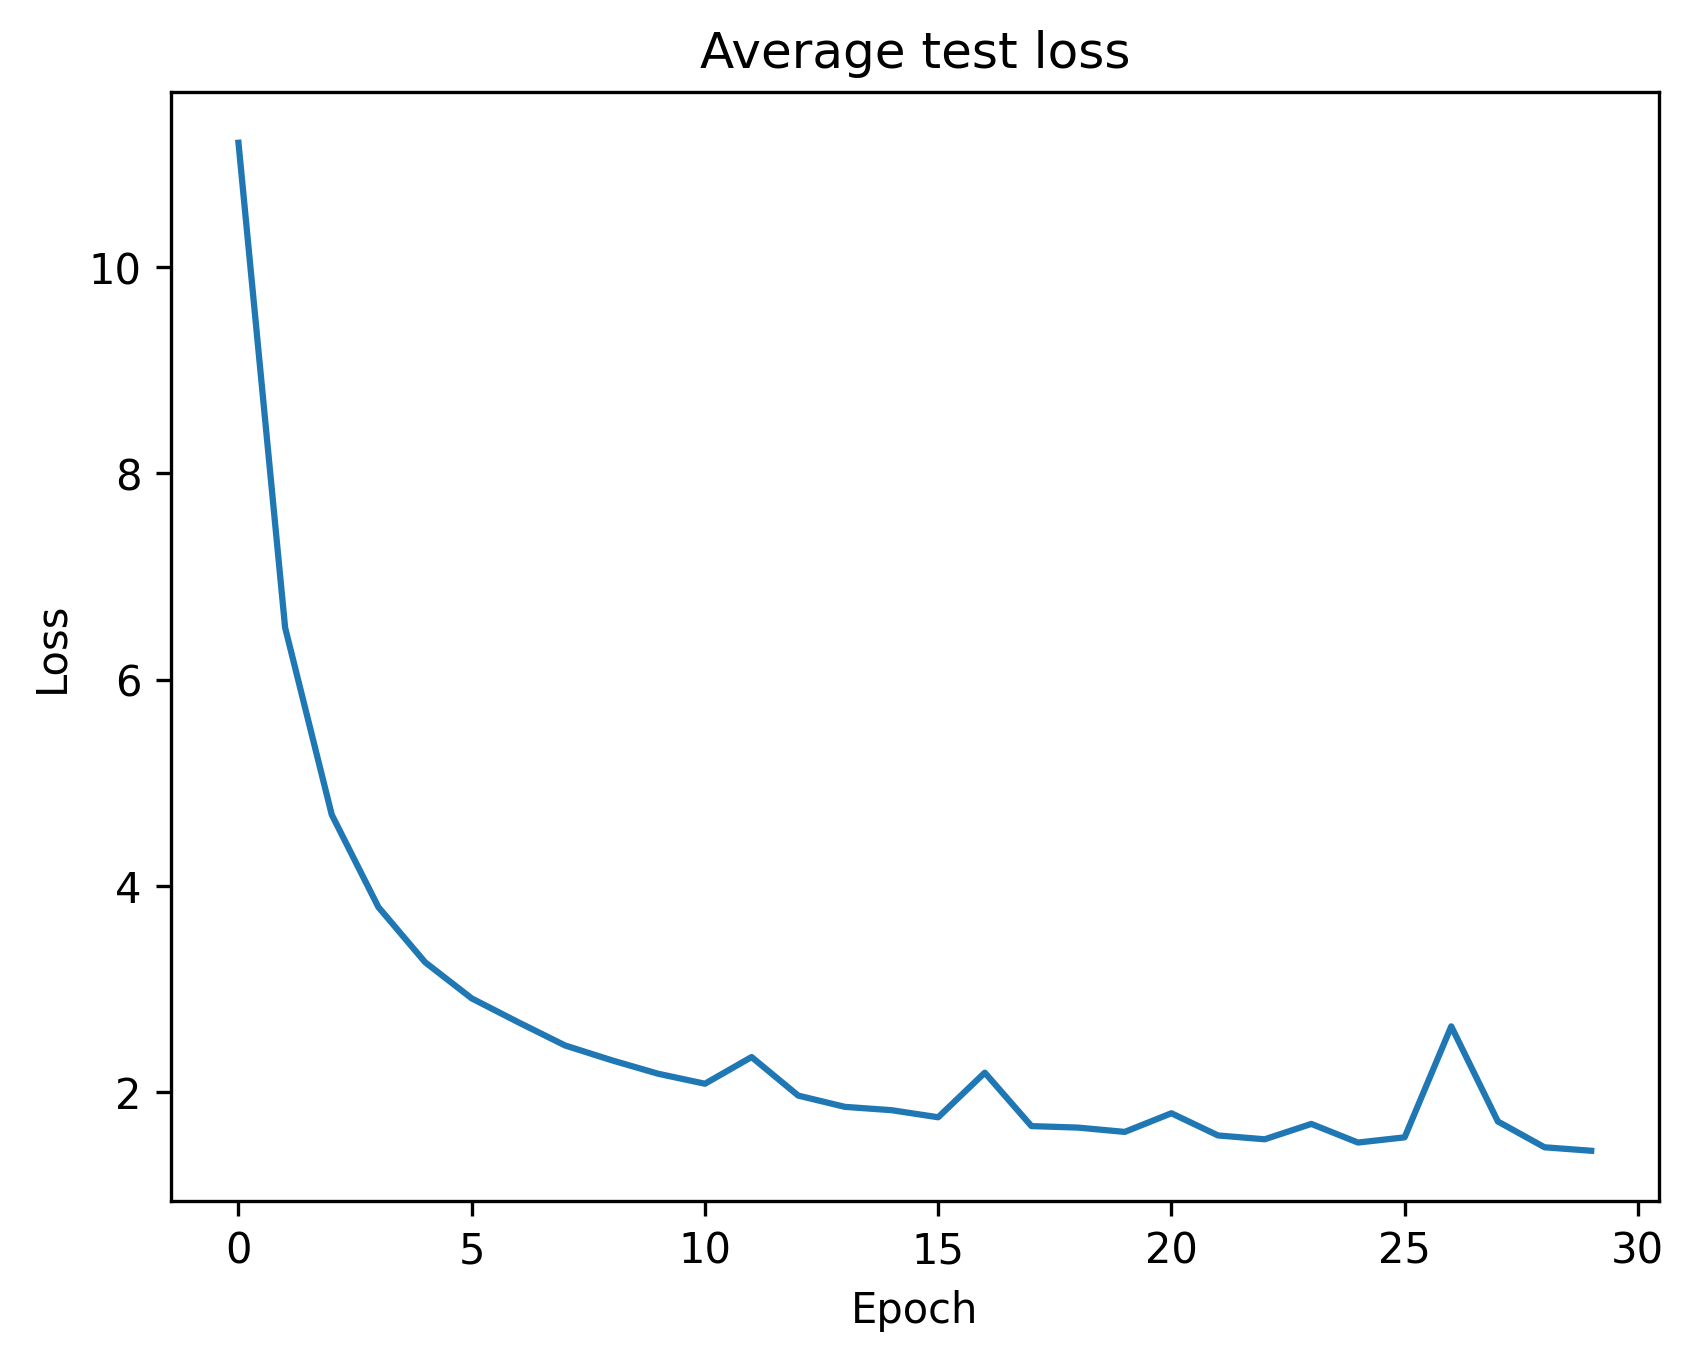

In [10]:
plt.figure(dpi=300)
plt.plot(test_loss)
plt.title("Average test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()